# Machine Learning Lecture 9: Exercise — Classification Problems with Python

## Correlated Quantities and Governing Quantities — "An Indicator That Predicts Well" Is Not Necessarily the Mechanism

Nagaoka University of Technology, Information and Management Systems Engineering, Theory of Machine Learning Laboratory, Gendo Kumoi

---

### Learning Goals

1. Handle next-token prediction by an LLM (Large Language Model) as a real example of the **indirect prediction** covered in Lecture 8
2. Understand how the **total variation distance** from Lecture 2 connects to actual acceptance decisions
3. Compare two candidate indicators using logistic regression and the **AUC** (Area Under the ROC Curve)
4. Explain, from numbers you measured yourself, that **an indicator that predicts well and the quantity that governs a phenomenon are different things**

### Structure of This Session

| Section | Content | Approx. time |
|---|---|---|
| 1 | Review of Lecture 8 and today's question | 10 min |
| 2 | Speculative decoding and acceptance (definition and theorem) | 20 min |
| 3 | Reading the real data | 10 min |
| 4 | Predicting acceptance with entropy | 20 min |
| 5 | **Another indicator** and the AUC showdown | 15 min |
| 6 | Why does this happen? — correlated quantities and governing quantities | 15 min |

Approximate total time: **80–90 min**

---

### Data Used Today

This exercise uses data actually measured in the Kumoi Laboratory (21,963 slots).
It is research data for a paper in preparation, so **please do not redistribute it outside the class**.

## 0. Setting Up the Environment

In [1]:
!pip install -q statsmodels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(20261103)
print("Ready")



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Ready


## 1. Review of Lecture 8 and Today's Question

### 1.1 What We Said in Lecture 8

There were two routes to prediction.

| | What the evaluation criterion is attached to | Procedure |
|---|---|---|
| **Indirect prediction** | Structure $\theta$ | Estimate the structure, then predict |
| **Direct prediction** | Prediction target $y_{n+1}$ | Predict without estimating the structure |

And we repeated the following caution.

> **Optimal structure estimation does not guarantee performance in prediction**

### 1.2 An LLM Performs Indirect Prediction

An LLM outputs a probability distribution over the vocabulary from the context and selects one token from it.
Because it goes through a structure (the distribution), it is **indirect prediction**.

### 1.3 Today's Question

There are many quantities that describe properties of a distribution. Which of them
**governs** "whether the next token is right"?

Today we compare two candidates.

- Candidate 1: **entropy** $H_t$ (Lecture 2) — how spread out the distribution is
- Candidate 2: a quantity based on the **total variation distance** (Lecture 2) — how different two distributions are

## 2. Speculative Decoding and Acceptance

### 2.1 The Setting

A large model (the target) is accurate but slow. A small model (the draft) is fast but rough.
So we proceed as follows.

1. Let the draft model **guess** the next token
2. The target model **checks** that guess
3. If it passes, adopt it; if it fails, use the target's answer

This scheme is called **speculative decoding**. Passing the check is called
**acceptance**. The higher the acceptance rate, the greater the speedup.

**Definition 1** (acceptance, temperature 0)
At temperature 0 (greedy decoding), the draft's proposed token $x_q$ is accepted
if and only if it coincides with the most probable token of the target distribution $p$.

In [2]:
%%html
<svg width="720" height="210" xmlns="http://www.w3.org/2000/svg">
  <defs><style>
    .b{fill:#e8eef8;stroke:#1b3a6b;stroke-width:2}
    .r{fill:#f6e3e0;stroke:#c0392b;stroke-width:2}
    .t{font-family:'Helvetica','Arial',sans-serif;font-size:13px;fill:#2c3e50}
    .s{font-family:'Helvetica','Arial',sans-serif;font-size:11px;fill:#7f8c8d}
    .ttl{font-family:'Helvetica','Arial',sans-serif;font-size:15px;font-weight:bold;fill:#1b3a6b}
  </style>
  <marker id="ar" markerWidth="9" markerHeight="9" refX="8" refY="3" orient="auto">
    <path d="M0,0 L0,6 L9,3 z" fill="#c0392b"/></marker></defs>
  <text x="360" y="22" text-anchor="middle" class="ttl">Acceptance in speculative decoding</text>

  <rect x="18" y="52" width="150" height="62" class="b" rx="6"/>
  <text x="93" y="78" text-anchor="middle" class="t">Draft model</text>
  <text x="93" y="99" text-anchor="middle" class="s">Fast but rough</text>

  <path d="M172,83 L228,83" stroke="#c0392b" stroke-width="2.4" fill="none" marker-end="url(#ar)"/>
  <text x="200" y="72" text-anchor="middle" class="s">Propose $x_q$</text>

  <rect x="233" y="52" width="160" height="62" class="b" rx="6"/>
  <text x="313" y="78" text-anchor="middle" class="t">Target model</text>
  <text x="313" y="99" text-anchor="middle" class="s">Accurate but slow</text>

  <path d="M397,83 L453,83" stroke="#c0392b" stroke-width="2.4" fill="none" marker-end="url(#ar)"/>
  <text x="425" y="72" text-anchor="middle" class="s">Check</text>

  <rect x="458" y="30" width="118" height="48" class="b" rx="6"/>
  <text x="517" y="59" text-anchor="middle" class="t">Accept</text>
  <rect x="458" y="92" width="118" height="48" class="r" rx="6"/>
  <text x="517" y="121" text-anchor="middle" class="t">Reject</text>

  <text x="640" y="60" text-anchor="middle" class="s">Proposal matches</text>
  <text x="640" y="78" text-anchor="middle" class="s">the most probable</text>
  <text x="640" y="122" text-anchor="middle" class="s">No match</text>

  <text x="360" y="175" text-anchor="middle" class="t">The higher the acceptance rate, the faster the whole process</text>
  <text x="360" y="196" text-anchor="middle" class="s">→ We want to know what decides acceptance</text>
</svg>


### 2.2 Relation to the Total Variation Distance

In Lecture 2, we introduced the **total variation distance** as a quantity that measures the difference between two distributions.

$$\mathrm{TV}(p,q)=\frac{1}{2}\sum_x \bigl|p(x)-q(x)\bigr|$$

At temperature 0, the draft deterministically outputs a single token $x_q$, so
the draft's "distribution" is the **point mass** $\delta_{x_q}$, with all its mass on $x_q$.

**Theorem 1** (total variation distance to a point mass)
$$\mathrm{TV}\bigl(p,\ \delta_{x_q}\bigr) = 1 - p(x_q)
\qquad\text{that is,}\qquad 1-\mathrm{TV}\bigl(p,\ \delta_{x_q}\bigr) = p(x_q)$$

**Proof**
By definition,
$$\mathrm{TV}(p,\delta_{x_q})=\frac{1}{2}\left[\bigl|p(x_q)-1\bigr|+\sum_{y\neq x_q}\bigl|p(y)-0\bigr|\right]$$
The first term on the right-hand side is $1-p(x_q)$, and the second is $\sum_{y\neq x_q}p(y)=1-p(x_q)$.
Therefore $\mathrm{TV}=\frac{1}{2}\bigl[(1-p(x_q))+(1-p(x_q))\bigr]=1-p(x_q)$. ∎

**Why this matters**
$1-\mathrm{TV}$ is exactly "the probability that the draft's proposed token has under the target distribution."
In other words, it is **a measurable quantity**. The column
`draft_p_under_tgt` in the data corresponds to it.

In [14]:
# Numerical check of Theorem 1: verify the identity with random distributions and arbitrary tokens

def tv(p, q):
    """Total variation distance (exactly the definition from Lecture 2)"""
    return 0.5 * np.sum(np.abs(np.asarray(p) - np.asarray(q)))

rng = np.random.default_rng(0)
print("Numerical check of Theorem 1   TV(p, δ_x) = 1 - p(x)")
print("=" * 58)
for trial in range(5):
    k = int(rng.integers(3, 9))
    p = rng.dirichlet(np.ones(k))
    x = int(rng.integers(k))
    delta = np.zeros(k); delta[x] = 1.0
    lhs, rhs = tv(p, delta), 1 - p[x]
    print(f"  k={k}  x={x}  TV={lhs:.6f}   1-p(x)={rhs:.6f}   diff={abs(lhs-rhs):.2e}")
    assert abs(lhs - rhs) < 1e-12, "Theorem 1 does not hold"
print("\n✓ Theorem 1 held in every trial.")


Numerical check of Theorem 1   TV(p, δ_x) = 1 - p(x)
  k=8  x=5  TV=0.909800   1-p(x)=0.909800   diff=0.00e+00
  k=6  x=5  TV=0.887523   1-p(x)=0.887523   diff=1.11e-16
  k=3  x=2  TV=0.307021   1-p(x)=0.307021   diff=0.00e+00
  k=5  x=0  TV=0.966923   1-p(x)=0.966923   diff=1.11e-16
  k=5  x=4  TV=0.950460   1-p(x)=0.950460   diff=1.11e-16

✓ Theorem 1 held in every trial.


In [4]:
# Even with the same distribution and the same entropy, 1-TV changes with the proposed token

def entropy_nat(p):
    p = np.asarray(p, float); p = p[p > 0]
    return float(-np.sum(p * np.log(p)))

p = np.array([0.5, 0.3, 0.2])
print(f"Target distribution p = {p}")
print(f"Entropy H(p) = {entropy_nat(p):.4f} nat  ← the same whatever the draft is")
print()
print("Proposed token    1-TV = p(x_q)   Acceptance at temp. 0")
print("-" * 50)
for i, name in enumerate(["most probable (1st)", "2nd", "3rd"]):
    print(f"  {name:<14}{p[i]:>10.2f}        {'accept' if i == 0 else 'reject'}")
print()
print("→ Entropy does not look at \"what the draft is\" at all.")
print("   1-TV, on the other hand, changes with each draft. Which one seems to govern acceptance?")


Target distribution p = [0.5 0.3 0.2]
Entropy H(p) = 1.0297 nat  ← the same whatever the draft is

Proposed token    1-TV = p(x_q)   Acceptance at temp. 0
--------------------------------------------------
  most probable (1st)      0.50        accept
  2nd                 0.30        reject
  3rd                 0.20        reject

→ Entropy does not look at "what the draft is" at all.
   1-TV, on the other hand, changes with each draft. Which one seems to govern acceptance?


## 3. Reading the Real Data

We use data on 21,963 slots measured in the Kumoi Laboratory.

| Column | Meaning |
|---|---|
| `H_t` | Entropy $H_t$ of the target distribution [nat] |
| `draft_p_under_tgt` | Probability of the draft's proposed token under the target distribution = $1-\mathrm{TV}$ |
| `match` | Acceptance at temperature 0 (1: accepted, 0: rejected) |
| `tgt_top1_p` | Maximum probability of the target distribution |
| `k` | Position within the draft (1–8) |
| `task_type` | code / conversation / creative |

### 3.1 How to Use the CSV File

The data is distributed on ILIAS as the CSV file `ht_accept_tokens_k8.csv`.
The notebook does not contain the data, so load it as follows.

1. Download `ht_accept_tokens_k8.csv` from ILIAS and save it on your computer (do not rename it)
2. Run the code cell below (leave `DATA_URL` empty)
3. A "Choose files" button appears. Press it and select the CSV you saved
4. If you see "Shape: 21,963 rows × 14 columns", it worked (it may take a few seconds)

Notes:

- On Colab, an uploaded file disappears when you close the browser or leave it idle for a while. If it disappears, start again from step 2
- If you run the notebook in Jupyter on your own computer, put the CSV in the same folder as the notebook and no upload is needed
- Do not redistribute this data outside the course

In [5]:
# ========== Where to get the data ==========
DATA_URL = ""  # @param {type: "string"}
# ====================================
# If you use the CSV distributed on ILIAS, run this cell with the box empty and choose the file with the button that appears. (If you were given a URL instead, paste it here.)

import io, os

CSV_NAME = "ht_accept_tokens_k8.csv"
df = None

if os.path.exists(CSV_NAME):                      # 1) already available locally
    df = pd.read_csv(CSV_NAME)
    print(f"Loaded local file: {CSV_NAME}")
elif DATA_URL:                                     # 2) fetch from URL
    df = pd.read_csv(DATA_URL)
    df.to_csv(CSV_NAME, index=False)
    print(f"Loaded from URL: {DATA_URL}")
else:                                              # 3) manual upload
    try:
        from google.colab import files
        print(f"Please select and upload {CSV_NAME}.")
        up = files.upload()
        name = list(up.keys())[0]
        df = pd.read_csv(io.BytesIO(up[name]))
        df.to_csv(CSV_NAME, index=False)
    except ImportError:
        raise RuntimeError("Set DATA_URL, or put the CSV in the same folder.")

print(f"\nShape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df[["task_type", "k", "H_t", "draft_p_under_tgt", "match", "tgt_top1_p"]].head()


Loaded local file: ht_accept_tokens_k8.csv

Shape: 21,963 rows × 14 columns


,task_type,k,H_t,draft_p_under_tgt,match,tgt_top1_p
0,conversation,1,0.00243,0.99983,1,0.99983
1,conversation,2,0.51249,0.79738,1,0.79738
2,conversation,3,0.00120,0.99990,1,0.99990
3,conversation,4,0.00090,0.99994,1,0.99994
4,conversation,5,0.00151,0.00014,0,0.99985


Breakdown of acceptance (match):
match
accepted    12827
rejected     9136

Overall acceptance rate: 0.5840

H_t          : min 0.000  max 5.415  mean 0.492 nat
1-TV         : min 0.000  max 1.000


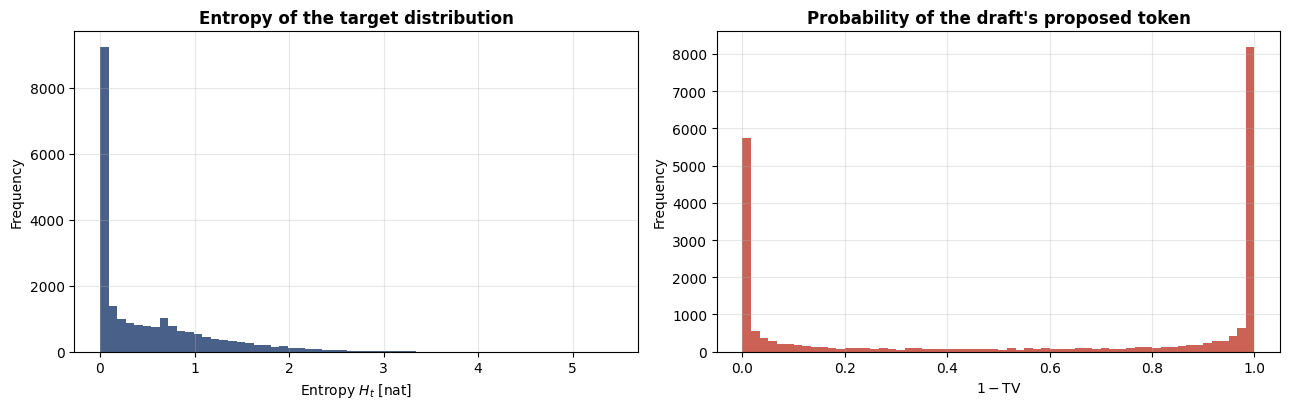

In [6]:
# Overview of the data
print("Breakdown of acceptance (match):")
print(df["match"].value_counts().rename({1: "accepted", 0: "rejected"}).to_string())
print(f"\nOverall acceptance rate: {df['match'].mean():.4f}")
print(f"\nH_t          : min {df.H_t.min():.3f}  max {df.H_t.max():.3f}  mean {df.H_t.mean():.3f} nat")
print(f"1-TV         : min {df.draft_p_under_tgt.min():.3f}  max {df.draft_p_under_tgt.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(df.H_t, bins=60, color="#1b3a6b", alpha=0.8)
axes[0].set_xlabel("Entropy $H_t$ [nat]"); axes[0].set_ylabel("Frequency")
axes[0].set_title("Entropy of the target distribution", fontweight="bold")
axes[1].hist(df.draft_p_under_tgt, bins=60, color="#c0392b", alpha=0.8)
axes[1].set_xlabel(r"$1-\mathrm{TV}$"); axes[1].set_ylabel("Frequency")
axes[1].set_title("Probability of the draft's proposed token", fontweight="bold")
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 4. Predicting Acceptance with Entropy

First, we naively form the hypothesis "the more spread out the distribution, the less likely acceptance is."
This is a quite plausible hypothesis.

     interval    n  accept_rate  lower  upper  center
(-0.001, 0.1] 9444       0.8658 0.8588 0.8726  0.0156
   (0.1, 0.3] 2459       0.5653 0.5456 0.5847  0.1896
   (0.3, 0.5] 1833       0.4954 0.4725 0.5182  0.3969
   (0.5, 0.8] 2812       0.4083 0.3902 0.4265  0.6551
   (0.8, 1.2] 2414       0.2920 0.2742 0.3105  0.9847
   (1.2, 1.8] 1931       0.1911 0.1742 0.2092  1.4657
   (1.8, 2.5]  847       0.1370 0.1154 0.1618  2.0861
  (2.5, 10.0]  223       0.0628 0.0378 0.1026  2.8899


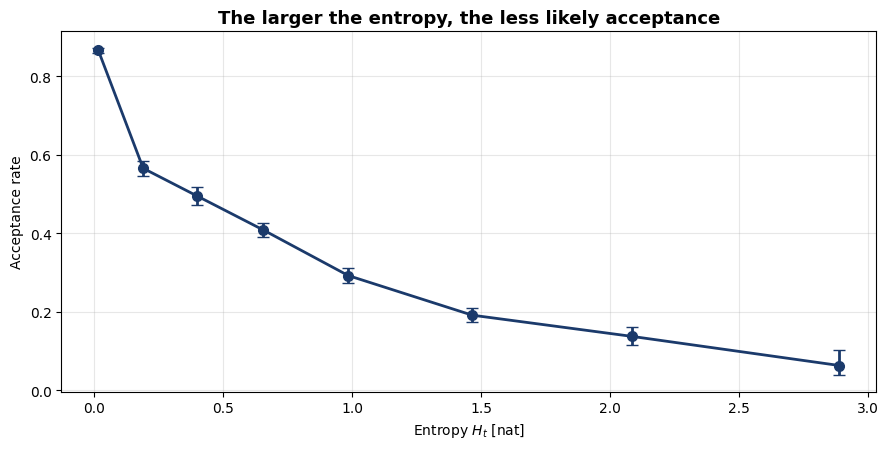

→ Beautifully monotonic. The hypothesis appears to be supported.


In [7]:
# Acceptance rate per entropy band (with Wilson confidence intervals)

def wilson(k, n, z=1.96):
    """Wilson confidence interval for a binomial proportion. Does not break down even for bands with small n."""
    if n == 0: return (np.nan, np.nan)
    ph = k / n
    d = 1 + z**2 / n
    c = (ph + z**2 / (2*n)) / d
    h = z * np.sqrt(ph*(1-ph)/n + z**2/(4*n**2)) / d
    return c - h, c + h

bins = [0, 0.1, 0.3, 0.5, 0.8, 1.2, 1.8, 2.5, 10]
df["H_bin"] = pd.cut(df.H_t, bins, include_lowest=True)
rows = []
for b, g in df.groupby("H_bin", observed=True):
    lo, hi = wilson(int(g["match"].sum()), len(g))
    rows.append({"interval": str(b), "n": len(g), "accept_rate": g["match"].mean(),
                 "lower": lo, "upper": hi, "center": g.H_t.mean()})
tab = pd.DataFrame(rows)
print(tab.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.errorbar(tab["center"], tab["accept_rate"],
            yerr=[tab["accept_rate"] - tab["lower"], tab["upper"] - tab["accept_rate"]],
            fmt="o-", color="#1b3a6b", lw=2, capsize=4, ms=7)
ax.set_xlabel("Entropy $H_t$ [nat]"); ax.set_ylabel("Acceptance rate")
ax.set_title("The larger the entropy, the less likely acceptance", fontsize=13, fontweight="bold")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("→ Beautifully monotonic. The hypothesis appears to be supported.")


In [8]:
# Logistic regression (fitting the logistic function from Lecture 8 to real data)
import statsmodels.api as sm

X = sm.add_constant(df[["H_t"]])
res = sm.Logit(df["match"], X).fit(disp=0)

beta1 = res.params["H_t"]
or_ = np.exp(beta1)
ci = np.exp(res.conf_int().loc["H_t"])
print("Logistic regression   P(accept) = g(β0 + β1·H_t)")
print("=" * 54)
print(f"  β1       = {beta1:.4f}")
print(f"  odds ratio = exp(β1) = {or_:.4f}")
print(f"  95% CI   = [{ci[0]:.3f}, {ci[1]:.3f}]")
print(f"  pseudo R² = {res.prsquared:.4f}")
print()
print(f"→ When H_t increases by 1 nat, the odds of acceptance are multiplied by about {or_:.2f}.")
print("   This is a strong association.")


Logistic regression   P(accept) = g(β0 + β1·H_t)
  β1       = -2.2119
  odds ratio = exp(β1) = 0.1095
  95% CI   = [0.102, 0.117]
  pseudo R² = 0.2079

→ When H_t increases by 1 nat, the odds of acceptance are multiplied by about 0.11.
   This is a strong association.


In [9]:
# AUC: the proportion of pairs in which the accepted row has the higher indicator value
from scipy.stats import rankdata

def auc(y, score):
    """AUC as the Mann-Whitney statistic. Ties are handled with average ranks."""
    y = np.asarray(y); s = np.asarray(score, float)
    r = rankdata(s)
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def roc(y, score, n=200):
    """ROC curve (Receiver Operating Characteristic).

    The trajectory of (false positive rate, true positive rate) as the threshold varies.
    The area under this curve is the AUC.
    """
    y = np.asarray(y); s = np.asarray(score, float)
    ths = np.quantile(s, np.linspace(0, 1, n))
    tpr = [( (s >= t) & (y == 1) ).sum() / (y == 1).sum() for t in ths]
    fpr = [( (s >= t) & (y == 0) ).sum() / (y == 0).sum() for t in ths]
    return np.array(fpr), np.array(tpr)

auc_H = auc(df["match"], -df["H_t"])
print(f"AUC(accept, -H_t) = {auc_H:.4f}")
print()
print("0.5 is random guessing, 1.0 is perfect. 0.83 is a fairly good value.")
print("Should we be satisfied here?")


AUC(accept, -H_t) = 0.8297

0.5 is random guessing, 1.0 is perfect. 0.83 is a fairly good value.
Should we be satisfied here?


## 5. Another Indicator

With Theorem 1 in Section 2, we confirmed that $1-\mathrm{TV}=p(x_q)$ is a measurable quantity.
Let us compare it on the same footing.

AUC showdown
  -H_t                 (entropy)          0.8297
  tgt_top1_p           (max probability)  0.8219
  draft_p_under_tgt    (1-TV)             0.9993


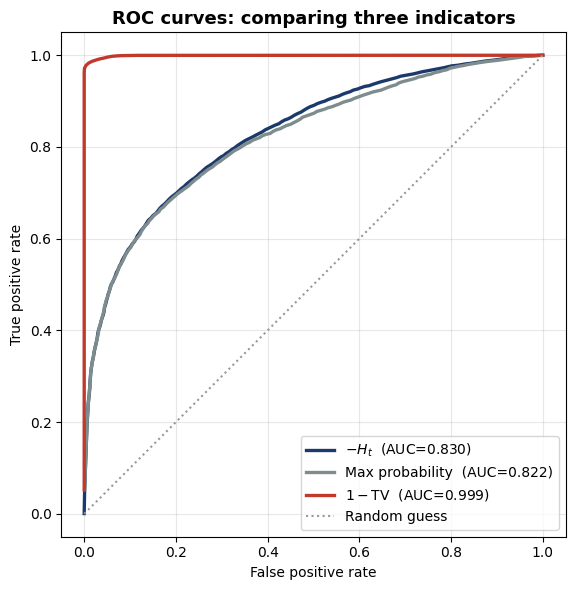

In [10]:
auc_tv = auc(df["match"], df["draft_p_under_tgt"])
auc_pmax = auc(df["match"], df["tgt_top1_p"])

print("AUC showdown")
print("=" * 50)
print(f"  -H_t                 (entropy)          {auc_H:.4f}")
print(f"  tgt_top1_p           (max probability)  {auc_pmax:.4f}")
print(f"  draft_p_under_tgt    (1-TV)             {auc_tv:.4f}")

fig, ax = plt.subplots(figsize=(6.4, 6))
for score, lab, color in [(-df["H_t"], f"$-H_t$  (AUC={auc_H:.3f})", "#1b3a6b"),
                          (df["tgt_top1_p"], f"Max probability  (AUC={auc_pmax:.3f})", "#7f8c8d"),
                          (df["draft_p_under_tgt"], f"$1-\\mathrm{{TV}}$  (AUC={auc_tv:.3f})", "#c0392b")]:
    f, t = roc(df["match"], score)
    ax.plot(f, t, lw=2.4, color=color, label=lab)
ax.plot([0, 1], [0, 1], ls=":", color="#999", lw=1.5, label="Random guess")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves: comparing three indicators", fontsize=13, fontweight="bold")
ax.legend(fontsize=10, loc="lower right"); ax.grid(alpha=0.3)
ax.set_aspect("equal")
plt.tight_layout(); plt.show()


## 6. Why Does This Happen? — Correlated Quantities and Governing Quantities

### 6.1 The Observed Facts

- Entropy has an AUC of 0.83. **It predicts quite well.**
- $1-\mathrm{TV}$ has an AUC close to 1.00. **It is almost perfect.**

### 6.2 Why Is $1-\mathrm{TV}$ Almost Perfect?

To be honest, it is because this is **almost an identity**.

Acceptance at temperature 0 was "the proposed token coincides with the most probable token" (Definition 1).
When they coincide, $p(x_q)$ takes the **maximum** of the distribution; when they do not,
it is smaller than the maximum. In other words, $1-\mathrm{TV}$ measures
**the mechanism of acceptance itself**.

<div style="border-left:4px solid #1b3a6b; padding-left:12px; margin:14px 0;">

**So this is not a story of "we found a good predictor."**
$1-\mathrm{TV}$ is the answer to the question "what decides acceptance?",
and the story is that this answer has also been confirmed numerically.

</div>

### 6.3 Then What Was the Entropy's 0.83?

Entropy **does not look at what the draft proposed at all**.
This is what we confirmed with the toy example in Section 2.2. Even so, it reaches 0.83.

The reason is that when the distribution is peaked ($H_t$ is small), the most probable token has a high probability,
and the draft also tends to guess it correctly. In other words, entropy is
**a quantity correlated with the mechanism** (a correlated quantity), not the mechanism itself (a governing quantity).

### 6.4 Today's Lesson

<div style="border-left:4px solid #c0392b; padding-left:12px; margin:14px 0;">

**A "fairly accurate" value such as AUC 0.83 does not mean that the indicator is the mechanism.**
And the more fairly accurate an indicator is, the less anyone questions it.

</div>

In the Lecture 1 guidance, we said:

> A "plausible criterion" may in fact not be the one that matters.
> Moreover, **the more often a criterion happens to be right, the less anyone questions it**

Today you have measured an actual example of this with your own hands.

In [11]:
# Check the claim of 6.2: is acceptance "the proposal coincides with the most probable token"?
same = (df["draft_tok"] == df["tgt_top1"]).astype(int)
print(f"Agreement rate between match and (draft_tok == tgt_top1): {(df['match'] == same).mean():.6f}")
assert (df["match"] == same).all(), "Definition 1 does not hold"

print("\nRelation between 1-TV and the max probability, for accepted and rejected rows:")
g = df.groupby("match").agg(
    n=("match", "size"),
    mean_1_TV=("draft_p_under_tgt", "mean"),
    mean_max_prob=("tgt_top1_p", "mean"),
    mean_H_t=("H_t", "mean"))
print(g.round(4).to_string())
print("\n→ In accepted rows, 1-TV equals the max probability (because proposal = most probable).")
print("   This is why the AUC is almost 1.")


Agreement rate between match and (draft_tok == tgt_top1): 1.000000

Relation between 1-TV and the max probability, for accepted and rejected rows:
           n  mean_1_TV  mean_max_prob  mean_H_t
match                                           
0       9136     0.0575         0.7215    0.8581
1      12827     0.9238         0.9238    0.2309

→ In accepted rows, 1-TV equals the max probability (because proposal = most probable).
   This is why the AUC is almost 1.


## 7. Organizing It as a Decision Mapping

Let us organize what we handled today by returning to the framework used since Lecture 1.

| | Input | Output | Evaluation criterion |
|---|---|---|---|
| Next-token prediction by an LLM | Context | The next single token | (Indirect prediction) via a distribution |
| Today's analysis | Tuples of $(H_t,\ 1-\mathrm{TV},\ \text{acceptance})$ | Which indicator explains acceptance | AUC |

**Points to note**
The "AUC" we used today is also just one evaluation criterion.
A high AUC means that "the ranking is correct,"
but it does not mean that "the mechanism has been captured."
Today's conclusion itself is an example of this.

## 8. Run It Yourself and Check

Condition: task=all, k=1-8   n=21,963
  accept rate   = 0.5840
  AUC(-H_t)     = 0.8297
  AUC(1-TV)     = 0.9993



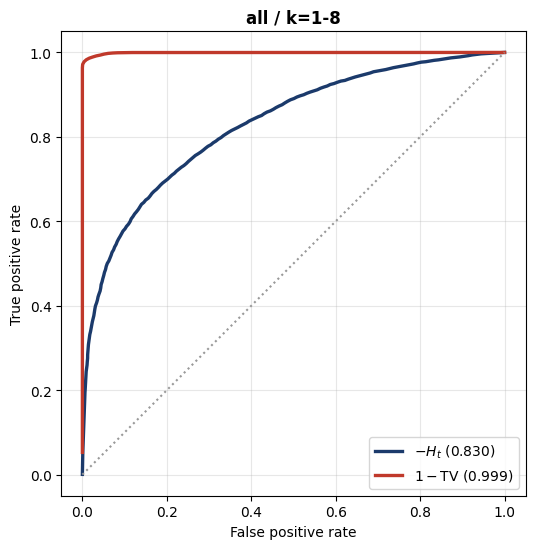

Does the order of the two AUCs change when you vary task or k?


In [15]:
# ========== Parameters to change ==========
task    = "all"  # @param ["all", "code", "conversation", "creative"]
k_min   = 1         # @param {type: "slider", min: 1, max: 8, step: 1}
k_max   = 8         # @param {type: "slider", min: 1, max: 8, step: 1}
# ===========================================

sub = df if task == "all" else df[df.task_type == task]
sub = sub[(sub.k >= k_min) & (sub.k <= k_max)]

if len(sub) < 50 or sub["match"].nunique() < 2:
    print("Too little data. Please widen the range.")
else:
    a_H  = auc(sub["match"], -sub["H_t"])
    a_TV = auc(sub["match"], sub["draft_p_under_tgt"])
    print(f"Condition: task={task}, k={k_min}-{k_max}   n={len(sub):,}")
    print(f"  accept rate   = {sub['match'].mean():.4f}")
    print(f"  AUC(-H_t)     = {a_H:.4f}")
    print(f"  AUC(1-TV)     = {a_TV:.4f}")
    print()
    fig, ax = plt.subplots(figsize=(6, 5.6))
    for score, lab, c in [(-sub["H_t"], f"$-H_t$ ({a_H:.3f})", "#1b3a6b"),
                          (sub["draft_p_under_tgt"], f"$1-$TV ({a_TV:.3f})", "#c0392b")]:
        f, t = roc(sub["match"], score)
        ax.plot(f, t, lw=2.4, color=c, label=lab)
    ax.plot([0, 1], [0, 1], ls=":", color="#999")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"{task} / k={k_min}-{k_max}", fontsize=12, fontweight="bold")
    ax.legend(fontsize=10, loc="lower right"); ax.grid(alpha=0.3); ax.set_aspect("equal")
    plt.tight_layout(); plt.show()
    print("Does the order of the two AUCs change when you vary task or k?")


## 9. Exercises

### Basic Problems

**Problem 1**
Verify Theorem 1 ($\mathrm{TV}(p,\delta_x)=1-p(x)$) by hand for the case $k=2$,
with $p=(0.7,0.3)$ and $x$ the first token.

**[Answer]**
Using Theorem 1, 



**Problem 2**
The odds ratio of the logistic regression was about $0.11$. This means that
"when $H_t$ increases by 1 nat, the odds of acceptance become about $1/9$."
Then, by what factor do the odds change when $H_t$ increases by 2 nat?

**[Answer]**



### Thinking Problems

**Problem 3**
Besides `match`, the data has a column called `accepted`.
The two do not coincide. Check the difference in the next cell, and discuss
**why they differ** and **which one should be used as the response variable**.

**[Answer]**
Indicates whether the draft model's proposed token at position $i$ equals the target model's greedy output ($x_q = \arg\max p$). 

Reflects the actual speculative decoding verification rule. Speculative decoding verifies draft tokens sequentially ($1, 2, \dots, k$). As soon as a mismatch occurs at position $j$, the verification loop terminates immediately, and all downstream draft tokens ($j+1, \dots, k$) are rejected (accepted = 0), regardless of whether their individual proposals matched the target model (match = 1).


**Problem 4**
Today the AUC of $1-\mathrm{TV}$ was close to 1.00 because it is the mechanism of acceptance
itself. Then, is this indicator **useful in practice**?
(Hint: consider what is needed to compute $1-\mathrm{TV}$.)

[Answer]

In [13]:
# Hint for Problem 3: the difference between match and accepted
print("Cross-tabulation:")
print(pd.crosstab(df["match"], df["accepted"], rownames=["match"], colnames=["accepted"]))
print()
print("match rate and accepted rate by position k:")
print(df.groupby("k")[["match", "accepted"]].mean().round(4).to_string())
print()
print("→ The larger k (the later the position in the draft sequence), the wider the gap.")
print("   In speculative decoding, once an earlier position is rejected, the later ones are not used.")
print("   accepted includes this structure, but match does not.")


Cross-tabulation:
accepted     0     1
match               
0         9136     0
1         6614  6213

match rate and accepted rate by position k:
    match  accepted
k                  
1  0.7152    0.7152
2  0.6370    0.4764
3  0.6086    0.3284
4  0.5917    0.2401
5  0.5668    0.1763
6  0.5459    0.1336
7  0.5129    0.1029
8  0.4898    0.0779

→ The larger k (the later the position in the draft sequence), the wider the gap.
   In speculative decoding, once an earlier position is rejected, the later ones are not used.
   accepted includes this structure, but match does not.


## 10. Summary and Discussion

### What We Learned

1. **Next-token prediction by an LLM is indirect prediction** (Lecture 8). It selects one token by way of a distribution.
2. **At temperature 0, $1-\mathrm{TV}=p(x_q)$** (Theorem 1). The total variation distance from Lecture 2
   becomes a directly measurable quantity.
3. **Entropy predicts well, with an AUC of 0.83, but it is not the mechanism.**
   It does not look at what the draft proposed at all.
4. **The more fairly accurate an indicator is, the less anyone questions it.**

### Reflection

| Question | Your answer before the exercise | Your answer after the exercise |
|---|---|---|
| Can we say that an indicator with a high AUC explains the phenomenon? | | |
| What is the difference between a "correlated quantity" and a "governing quantity"? | | |

### Advanced Tasks

**Task A**
When the AUC is computed for each `task_type`, it differs among code / conversation / creative.
Can this difference be called a difference in "task difficulty"?
(Hint: recall the discussion of confounding from Lecture 6.)

**Task B**
Run a multiple regression (logistic regression) with both `H_t` and `1-TV` as explanatory variables,
and check what happens to each coefficient. Use what you learned about multiple regression in Lecture 5.

**Task C**
Building on what you considered in Problem 4, state why both "an indicator usable in practice" and
"a quantity that explains the mechanism" are needed.

### Report Assignment (10 points)

1. The two AUC values you obtained in your own environment
   <br>
   **[Answer]**<br>
     AUC(-H_t)     = 0.8297<br>
     AUC(1-TV)     = 0.9993

2. Your answer to Problem 3 (which of `match` and `accepted` should be used, with reasons)
   <br>
   **[Answer]**
   <br>
   The reason that they are differ because, "match" indicates whether the draft model's proposed token at position $i$ equals the target model's top-1 token ($x_q = \arg\max p$). However, "accepted"Reflects the actual runtime execution of speculative decoding across a $k$-token draft block. Verification runs sequentially from position $1$ to $k$.
   <br>
   Use "match" as response variable. This is to examine how single-token distributional metrics predict whether a proposed token is accurate.

3. **Discussion**: to claim that an indicator "governs a phenomenon," what else must be shown
   besides predictive performance such as the AUC?

   In order to say that "an indicator governs a phenomenon", The quantity must explicitly enter the generative or decision-making process of the phenomenon.$1 - \mathrm{TV} = p(x_q)$ directly measures the target likelihood of the proposed token $x_q$, which defines the acceptance rule at temperature 0. Entropy $H_t$, by contrast, only measures the spread of the target distribution and ignores the draft proposal entirely.

**Grading is based on the depth of your discussion, not on predictive performance.**

---

### References

[1] The data in this exercise are measurement results from the Kumoi Laboratory's research on speculative decoding (in preparation for submission to TMLR).
    Please do not redistribute them outside the class.
[2] C.M. Bishop, *Pattern Recognition and Machine Learning*, Springer, 2006.